<a href="https://colab.research.google.com/github/2Bert0/Meus-projetos/blob/main/Segmenta%C3%A7%C3%A3o_de_clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

print("Pandas importado com sucesso! Versão:", pd.__version__)

Pandas importado com sucesso! Versão: 2.2.3


In [4]:

import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [5]:
import pandas as pd
import os

# Mostra onde os arquivos foram salvos e lista eles
print("Caminho dos dados:", path)
print("Arquivos na pasta:", os.listdir(path))

# Carregando as tabelas principais para o Pandas
df_clientes = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))
df_pedidos = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
df_itens = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))

print("\nTabelas carregadas com sucesso!")

Caminho dos dados: /kaggle/input/brazilian-ecommerce
Arquivos na pasta: ['olist_customers_dataset.csv', 'olist_sellers_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_order_items_dataset.csv', 'olist_products_dataset.csv', 'olist_geolocation_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv']

Tabelas carregadas com sucesso!


In [6]:
print("--- CLIENTES (Amostra) ---")
display(df_clientes.head(3))

print("\n--- PEDIDOS (Informações e Colunas) ---")
df_pedidos.info()

print("\n--- ITENS DOS PEDIDOS (Amostra) ---")
display(df_itens.head(3))

--- CLIENTES (Amostra) ---


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



--- PEDIDOS (Informações e Colunas) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

--- ITENS DOS PEDIDOS (Amostra) ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


In [7]:
# 1. Filtrar apenas pedidos com status 'delivered' (entregues)
pedidos_entregues = df_pedidos[df_pedidos['order_status'] == 'delivered'].copy()

print(f"Total de pedidos gerais: {len(df_pedidos)}")
print(f"Total de pedidos entregues filtrados: {len(pedidos_entregues)}")

# 2. Unir as tabelas de pedidos com os itens do pedido
# Usamos o 'order_id' como chave de ligação
df_pedido_item = pd.merge(pedidos_entregues, df_itens, on='order_id', how='inner')

# 3. Unir o resultado com a tabela de clientes para trazer o 'customer_unique_id'
# Na Olist, 'customer_id' muda por compra, mas 'customer_unique_id' é o cliente real.
df_completo = pd.merge(df_pedido_item, df_clientes[['customer_id', 'customer_unique_id']], on='customer_id', how='inner')

print("\nTabela unificada com sucesso! Dimensões finais (Linhas, Colunas):", df_completo.shape)
display(df_completo.head(3))

Total de pedidos gerais: 99441
Total de pedidos entregues filtrados: 96478

Tabela unificada com sucesso! Dimensões finais (Linhas, Colunas): (110197, 15)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,3a653a41f6f9fc3d2a113cf8398680e8


In [8]:
import numpy as np

# 1. Converter a coluna de data da compra para o formato de Data do Pandas
df_completo['order_purchase_timestamp'] = pd.to_datetime(df_completo['order_purchase_timestamp'])

# 2. Definir a "Data de Referência" (snapshot date)
# Como a base é antiga (termina em 2018), pegamos o dia seguinte à última compra registrada na base
data_referencia = df_completo['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
print(f"Data de referência (fim da base): {data_referencia}")

# 3. Calcular o valor total gasto por item (Preço + Frete)
df_completo['total_gasto'] = df_completo['price'] + df_completo['freight_value']

# 4. Agrupar por 'customer_unique_id' para calcular o RFM
rfm = df_completo.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (data_referencia - x.max()).days, # Recência: dias desde a última compra
    'order_id': 'nunique',                                                # Frequência: total de pedidos únicos
    'total_gasto': 'sum'                                                  # Monetário: total gasto acumulado
}).reset_index()

# 5. Renomear as colunas para ficar com a nomenclatura padrão do RFM
rfm.columns = ['customer_unique_id', 'Recencia', 'Frequencia', 'Monetario']

print("\nTabela RFM calculada com sucesso!")
print(f"Total de clientes únicos analisados: {len(rfm)}")
display(rfm.head())

Data de referência (fim da base): 2018-08-30 15:00:37

Tabela RFM calculada com sucesso!
Total de clientes únicos analisados: 93358


,customer_unique_id,Recencia,Frequencia,Monetario
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19
2,0000f46a3911fa3c0805444483337064,537,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Selecionar apenas as colunas de Recência, Frequência e Monetário
X = rfm[['Recencia', 'Frequencia', 'Monetario']]

# 2. Padronizar os dados (deixar com média 0 e desvio padrão 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Aplicar o K-Means (vamos dividir em 4 grupos / clusters)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# 4. Adicionar o grupo (cluster) de volta à nossa tabela de RFM
rfm['Cluster'] = kmeans.labels_

print("Clusterização concluída com sucesso!")
print("\nContagem de clientes por Cluster:")
print(rfm['Cluster'].value_counts())

display(rfm.head())

Clusterização concluída com sucesso!

Contagem de clientes por Cluster:
Cluster
1    50642
0    37526
2     2772
3     2418
Name: count, dtype: int64


,customer_unique_id,Recencia,Frequencia,Monetario,Cluster
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,1
2,0000f46a3911fa3c0805444483337064,537,1,86.22,0
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,0
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,0


/tmp/ipykernel_1108/465495911.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=medias_cluster, x='Monetario', y='Nome_Cluster', palette='viridis', ax=ax1)
/tmp/ipykernel_1108/465495911.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=medias_cluster, x='Recencia', y='Nome_Cluster', palette='magma', ax=ax2)


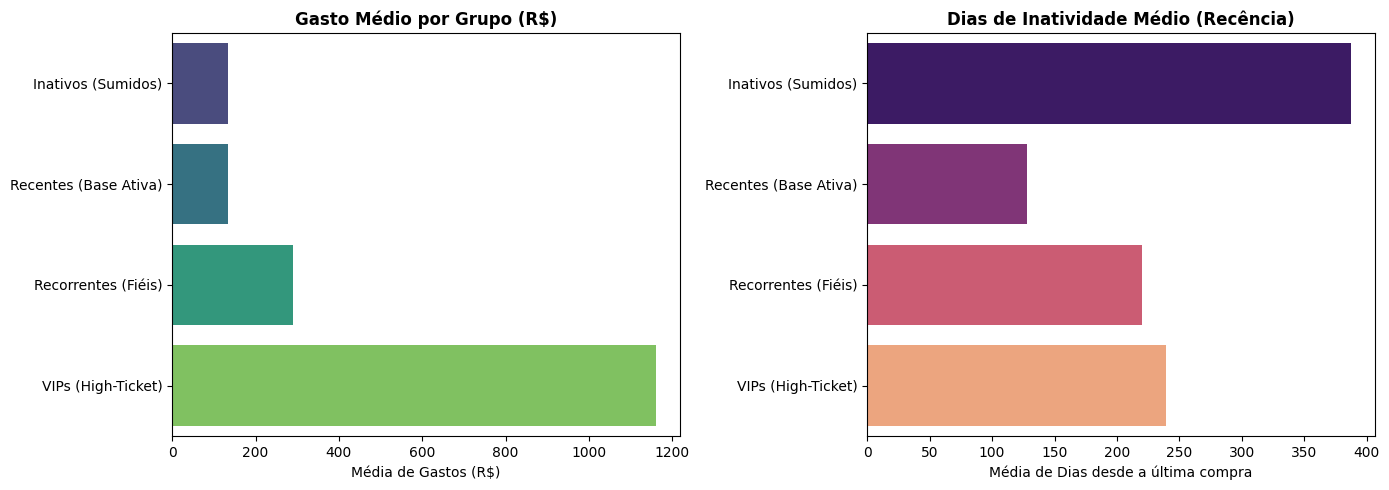


Gráfico gerado com sucesso! Agora dá para ver exatamente o peso de cada cluster.


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Renomear os clusters com nomes de negócio para facilitar a leitura no gráfico
dicionario_clusters = {
    0: 'Inativos (Sumidos)',
    1: 'Recentes (Base Ativa)',
    2: 'Recorrentes (Fiéis)',
    3: 'VIPs (High-Ticket)'
}

# Criamos uma cópia temporária para o gráfico com nomes amigáveis
rfm_grafico = rfm.copy()
rfm_grafico['Nome_Cluster'] = rfm_grafico['Cluster'].map(dicionario_clusters)

# 2. Calcular as médias para o gráfico
medias_cluster = rfm_grafico.groupby('Nome_Cluster')[['Recencia', 'Monetario']].mean().reset_index()

# 3. Configurar um gráfico duplo (um para Recência, outro para Monetário)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Valor Monetário Médio por Cluster
sns.barplot(data=medias_cluster, x='Monetario', y='Nome_Cluster', palette='viridis', ax=ax1)
ax1.set_title('Gasto Médio por Grupo (R$)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Média de Gastos (R$)')
ax1.set_ylabel('')

# Gráfico 2: Recência Média por Cluster
sns.barplot(data=medias_cluster, x='Recencia', y='Nome_Cluster', palette='magma', ax=ax2)
ax2.set_title('Dias de Inatividade Médio (Recência)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Média de Dias desde a última compra')
ax2.set_ylabel('')

plt.tight_layout()
plt.show()

print("\nGráfico gerado com sucesso! Agora dá para ver exatamente o peso de cada cluster.")